# 2. Análisis exploratorio (EDA)

Solo conjunto de train.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sys
from pathlib import Path

PROJECT_PATH = Path("..").resolve()
DATA_PATH = PROJECT_PATH / "data"
FIGURES_PATH = PROJECT_PATH / "figures"
sys.path.append(str(PROJECT_PATH))
RANDOM_STATE = 42

from predictor import TARGET

train_reservations = pd.read_csv(DATA_PATH / "train.csv")
overall_cancellation_rate = train_reservations[TARGET].mean()


def plot_cancellation_rate(column, ax, top_n=None, order=None):
    cancellation_rate = train_reservations.groupby(column)[TARGET].agg(["mean", "size"])
    if top_n:
        cancellation_rate = cancellation_rate.nlargest(top_n, "size")
    cancellation_rate = cancellation_rate.reindex(order) if order else cancellation_rate.sort_values("mean")
    ax.barh(cancellation_rate.index.astype(str), cancellation_rate["mean"], color="#3470a3", edgecolor="black")
    ax.axvline(overall_cancellation_rate, color="#e66101", linestyle="--", label="tasa global")
    for position, (rate, size) in enumerate(zip(cancellation_rate["mean"], cancellation_rate["size"])):
        ax.text(rate + 0.01, position, f"{rate:.0%} (n={size:,})", va="center", fontsize=8)
    ax.set_xlim(0, 1.25)
    ax.set_xlabel("Tasa de cancelación")
    ax.set_title(column, fontweight="bold")
    ax.legend(loc="lower right")

## 2.1 Balance de la variable objetivo

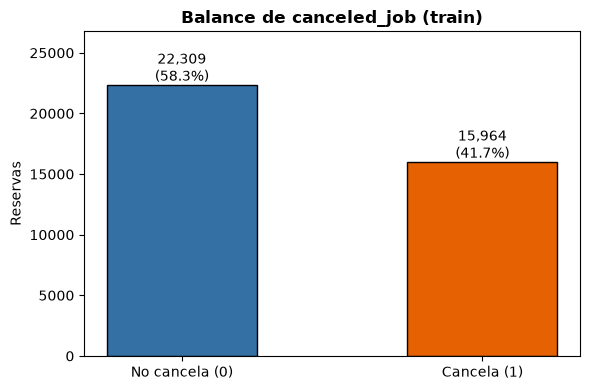

In [2]:
fig, ax = plt.subplots(figsize=(6, 4))
target_counts = train_reservations[TARGET].value_counts().sort_index()
bars = ax.bar(["No cancela (0)", "Cancela (1)"], target_counts.values, color=["#3470a3", "#e66101"], edgecolor="black", width=0.5)
ax.bar_label(bars, labels=[f"{count:,}\n({count / target_counts.sum():.1%})" for count in target_counts.values])
ax.set_ylim(0, target_counts.max() * 1.2)
ax.set_ylabel("Reservas")
ax.set_title("Balance de canceled_job (train)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES_PATH / "01_target_balance.png", dpi=300)
plt.show()

- 58% / 42%: desbalance moderado. La métrica de la competencia es **balanced accuracy** → se ajusta el umbral de decisión (notebook 6).

## 2.2 Tasa de cancelación por variable categórica

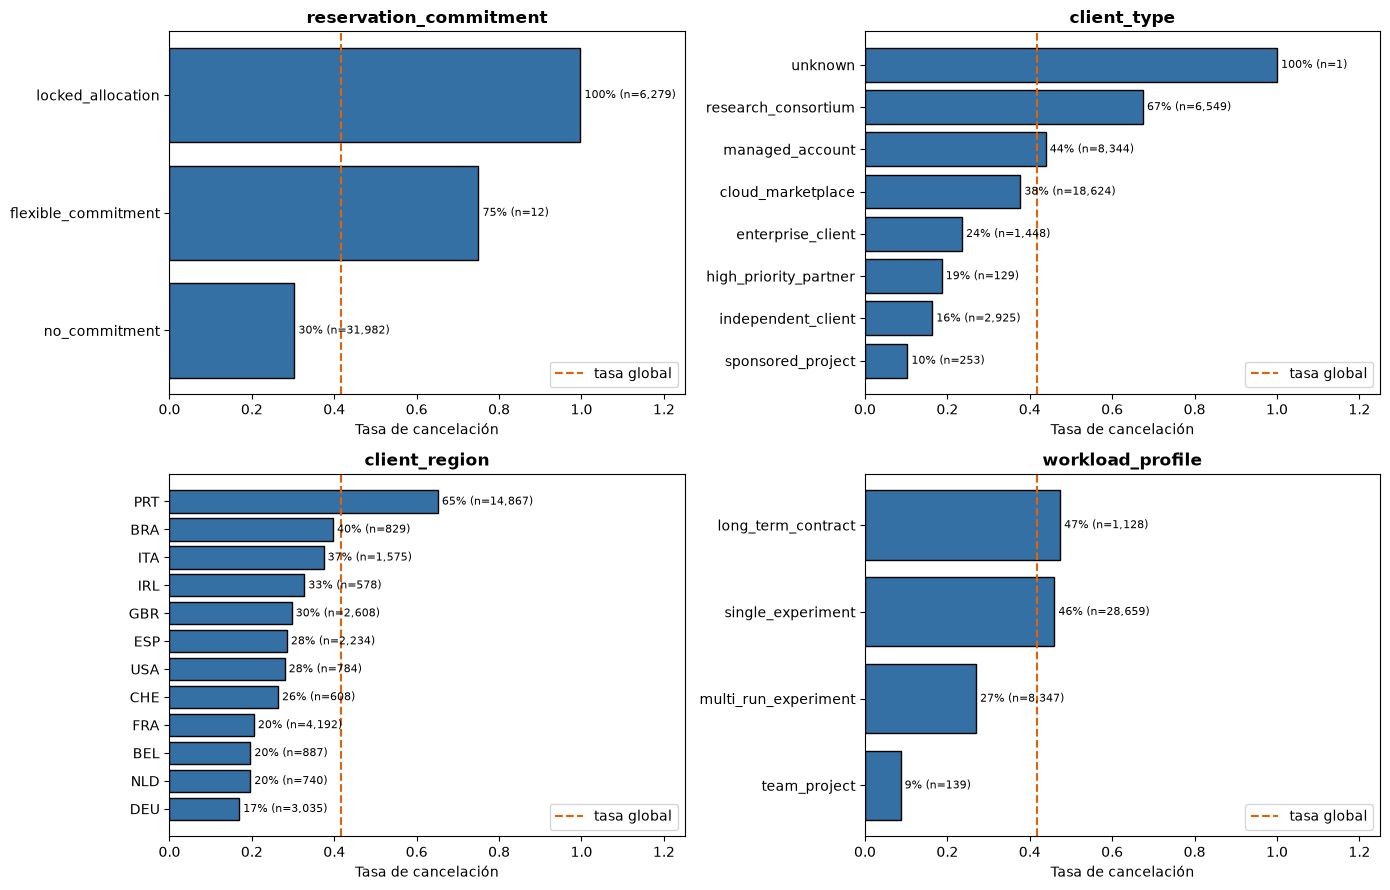

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_cancellation_rate("reservation_commitment", axes[0, 0])
plot_cancellation_rate("client_type", axes[0, 1])
plot_cancellation_rate("client_region", axes[1, 0], top_n=12)
plot_cancellation_rate("workload_profile", axes[1, 1])
plt.tight_layout()
fig.savefig(FIGURES_PATH / "02_cancellation_rate_categorical.png", dpi=300)
plt.show()

- `locked_allocation` cancela casi siempre (≈100%).
- `client_region` = PRT y `client_type` = research_consortium muy por encima de la media.

## 2.3 Antelación de la reserva (`hours_before_execution`)

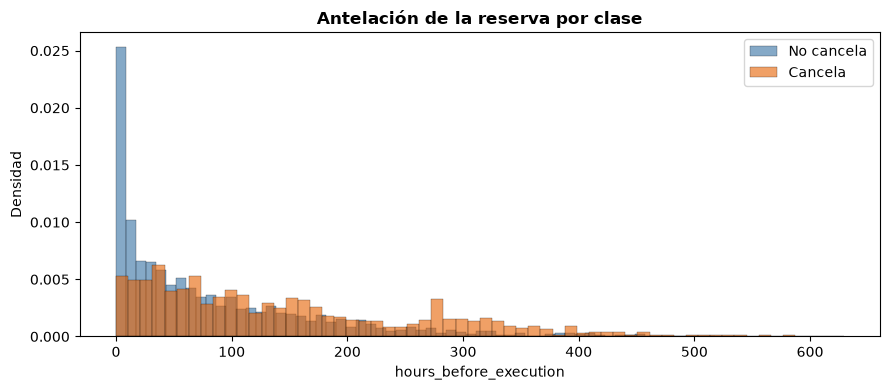

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for target_value, color, label in [(0, "#3470a3", "No cancela"), (1, "#e66101", "Cancela")]:
    ax.hist(train_reservations.loc[train_reservations[TARGET] == target_value, "hours_before_execution"],
            bins=60, density=True, alpha=0.6, color=color, label=label, edgecolor="black", linewidth=0.3)
ax.set_xlabel("hours_before_execution")
ax.set_ylabel("Densidad")
ax.set_title("Antelación de la reserva por clase", fontweight="bold")
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_PATH / "03_hours_before_execution.png", dpi=300)
plt.show()

- Las reservas hechas con mucha antelación cancelan bastante más.

## 2.4 Cambios de GPU, pedidos especiales y modificaciones

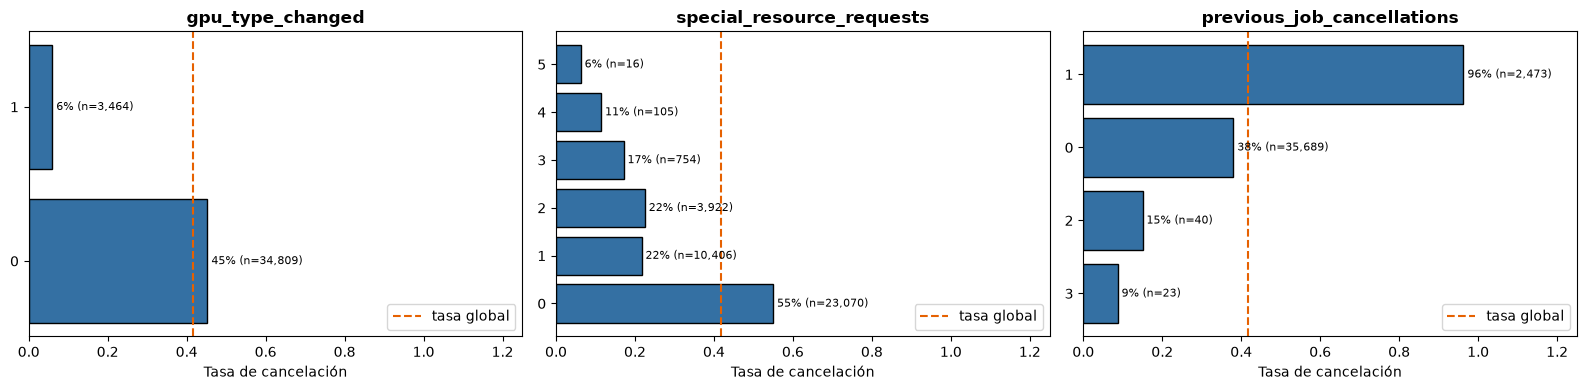

In [5]:
train_reservations["gpu_type_changed"] = (train_reservations["reserved_gpu_type"] != train_reservations["assigned_gpu_type"]).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plot_cancellation_rate("gpu_type_changed", axes[0], order=[0, 1])
plot_cancellation_rate("special_resource_requests", axes[1], order=[0, 1, 2, 3, 4, 5])
plot_cancellation_rate("previous_job_cancellations", axes[2], top_n=4)
plt.tight_layout()
fig.savefig(FIGURES_PATH / "04_cancellation_rate_requests.png", dpi=300)
plt.show()

- Si la GPU asignada difiere de la reservada casi no se cancela (la asignación se hace días antes de la ejecución → es información disponible).
- Más pedidos especiales → menos cancelaciones; cancelaciones previas → más cancelaciones.

## 2.5 Evolución temporal

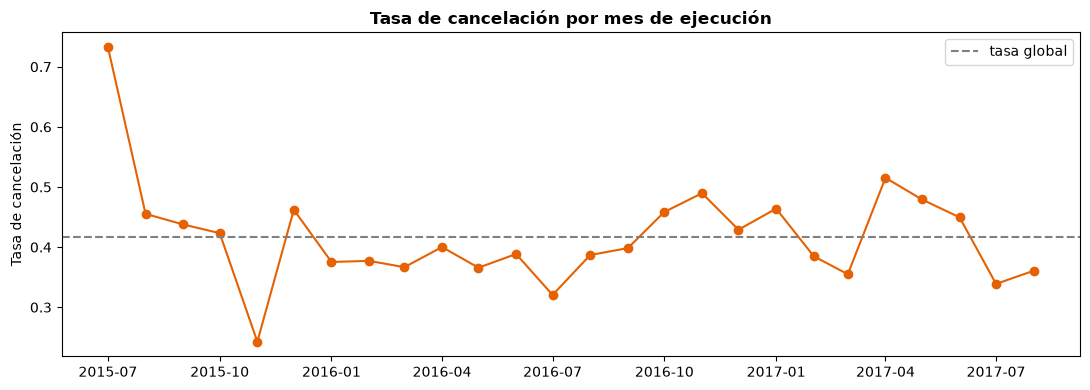

In [6]:
monthly_cancellation_rate = (train_reservations
                             .assign(execution_period=pd.to_datetime(dict(year=train_reservations["execution_year"],
                                                                         month=train_reservations["execution_month"], day=1)))
                             .groupby("execution_period")[TARGET].agg(["mean", "size"]))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly_cancellation_rate.index, monthly_cancellation_rate["mean"], marker="o", color="#e66101")
ax.axhline(overall_cancellation_rate, color="gray", linestyle="--", label="tasa global")
ax.set_ylabel("Tasa de cancelación")
ax.set_title("Tasa de cancelación por mes de ejecución", fontweight="bold")
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_PATH / "05_monthly_cancellation_rate.png", dpi=300)
plt.show()

## 2.6 Correlación entre variables numéricas

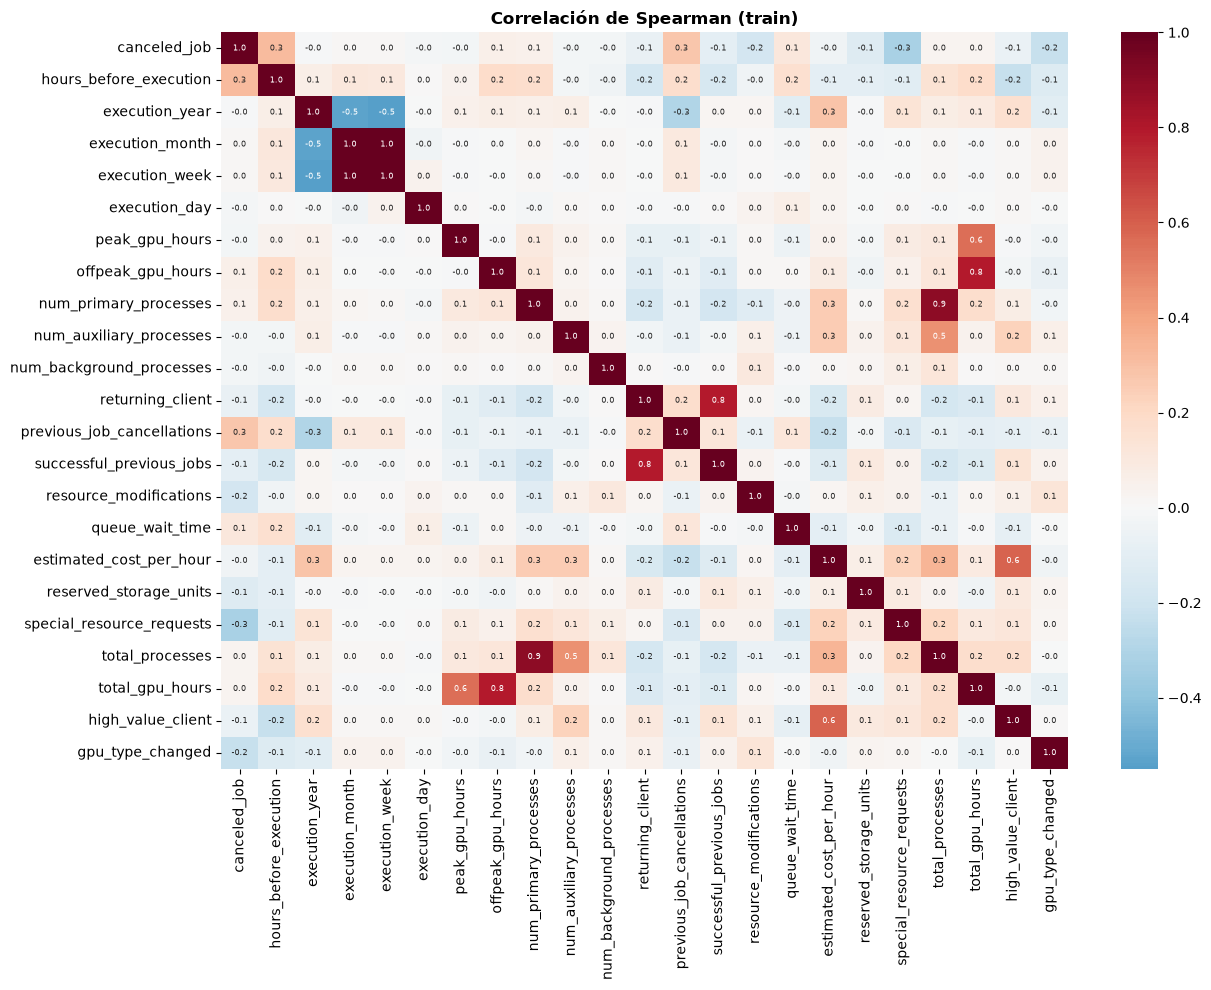

In [7]:
numeric_columns = train_reservations.select_dtypes("number").columns.drop(["organization_id", "orchestration_agent_id"])
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(train_reservations[numeric_columns].corr(method="spearman"), cmap="RdBu_r", center=0, ax=ax,
            annot=True, fmt=".1f", annot_kws={"size": 6})
ax.set_title("Correlación de Spearman (train)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES_PATH / "06_spearman_correlation.png", dpi=300)
plt.show()

- Redundancias esperables (`total_*` = suma de sus componentes, fecha en año/semana/mes).
- Los modelos finales son de árboles: la colinealidad no los afecta y no se eliminan variables.